
# MicroGrad: Scalar Automatic Differentiation Engine

**Deep Learning Assignment 1**

**Student:** Mireille Amir  
**Student ID:** 23P0186  
**University:** Ain Shams University  
**Course:** Deep Learning

---

## 1. Introduction

MicroGrad is a small scalar-based automatic differentiation engine inspired by Andrej Karpathy's MicroGrad.

The main objective of this project is to understand how automatic differentiation and backpropagation work internally without relying on deep learning frameworks such as PyTorch.

The implementation includes:

- Scalar value representation.
- Mathematical operations and operator overloading.
- Computational graph construction.
- Automatic gradient calculation.
- Backpropagation using the chain rule.
- Topological sorting.
- Neural network components including Neuron, Layer, and MLP.

## 2. Project Objectives

1. Understand computational graphs.
2. Implement automatic differentiation from scratch.
3. Apply the chain rule to calculate gradients.
4. Implement backpropagation using topological sorting.
5. Build a basic neural network using the implemented engine.
6. Train and evaluate a neural network on a sample dataset.

## 3. Implementation

The project is implemented in Python using two main modules:

- `engine.py`: Implements the Value class and automatic differentiation.
- `nn.py`: Implements Neuron, Layer, and Multi-Layer Perceptron (MLP).


In [1]:

import sys
import os
import math
import random
import matplotlib.pyplot as plt

# Add the project root to Python's import path
PROJECT_ROOT = os.path.abspath("..")

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.engine import Value
from src.nn import Neuron, Layer, MLP

print("MicroGrad modules imported successfully!")
print("Python executable:", sys.executable)


MicroGrad modules imported successfully!
Python executable: C:\Users\Victus\AppData\Local\Programs\Python\Python310\python.exe


In [2]:

# Create scalar values
a = Value(2.0, label="a")
b = Value(3.0, label="b")

# Perform mathematical operations
addition = a + b
multiplication = a * b
power = a ** 2

print("Addition:", addition.data)
print("Multiplication:", multiplication.data)
print("Power:", power.data)


Addition: 5.0
Multiplication: 6.0
Power: 4.0


In [3]:

# Define the computational graph
x = Value(2.0, label="x")
y = Value(3.0, label="y")

z = x * y + x ** 2

# Calculate gradients
z.backward()

print("Output:", z.data)
print("Gradient dz/dx:", x.grad)
print("Gradient dz/dy:", y.grad)


Output: 10.0
Gradient dz/dx: 7.0
Gradient dz/dy: 2.0



## 4. Computational Graph Visualization

A computational graph represents mathematical operations as connected nodes.

Each node represents a variable or an operation, while the edges represent dependencies between them.

For this demonstration, we use:

\[
z = xy + x^2
\]

The graph illustrates how the input variables are combined to produce the final output.

During backpropagation, gradients flow backward through the graph using the chain rule.


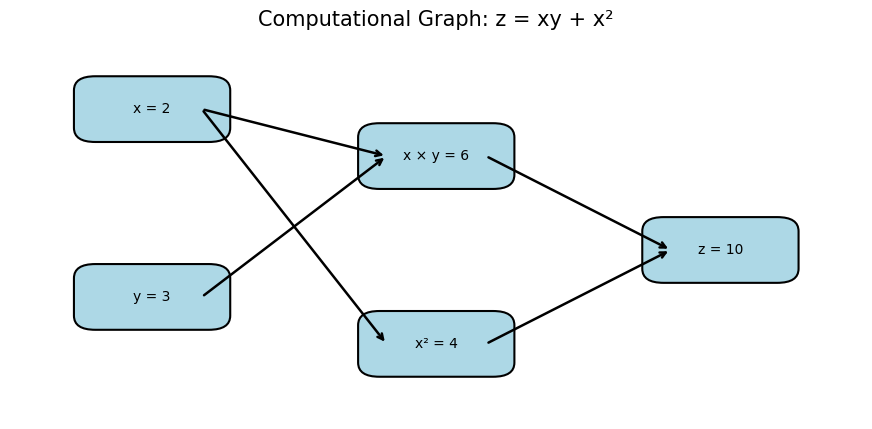

In [4]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Define graph node positions
positions = {
    "x": (0, 2),
    "y": (0, 0),
    "multiply": (2, 1.5),
    "power": (2, -0.5),
    "add": (4, 0.5)
}

fig, ax = plt.subplots(figsize=(11, 5))

# Draw arrows between nodes
edges = [
    ("x", "multiply"),
    ("y", "multiply"),
    ("x", "power"),
    ("multiply", "add"),
    ("power", "add")
]

for start, end in edges:
    x1, y1 = positions[start]
    x2, y2 = positions[end]

    ax.annotate(
        "",
        xy=(x2 - 0.35, y2),
        xytext=(x1 + 0.35, y1),
        arrowprops=dict(arrowstyle="->", lw=1.8)
    )

# Node labels
labels = {
    "x": "x = 2",
    "y": "y = 3",
    "multiply": "x × y = 6",
    "power": "x² = 4",
    "add": "z = 10"
}

# Draw nodes
for node, (x_pos, y_pos) in positions.items():
    box = FancyBboxPatch(
        (x_pos - 0.4, y_pos - 0.2),
        0.8, 0.4,
        boxstyle="round,pad=0.15",
        edgecolor="black",
        facecolor="lightblue",
        linewidth=1.5
    )

    ax.add_patch(box)

    ax.text(
        x_pos, y_pos,
        labels[node],
        ha="center",
        va="center",
        fontsize=10
    )

ax.set_title("Computational Graph: z = xy + x²", fontsize=15)
ax.set_xlim(-1, 5)
ax.set_ylim(-1.3, 2.8)
ax.axis("off")

plt.show()



## 5. Backpropagation and Gradient Calculation

Backpropagation calculates the gradients of the final output with respect to the input variables.

For our example:

\[
z = xy + x^2
\]

Using the sum rule and product rule:

\[
\frac{\partial z}{\partial x}=y+2x
\]

\[
\frac{\partial z}{\partial y}=x
\]

Substituting \(x=2\) and \(y=3\):

\[
\frac{\partial z}{\partial x}=3+2(2)=7
\]

\[
\frac{\partial z}{\partial y}=2
\]

The MicroGrad engine automatically calculates these derivatives through its backward propagation mechanism.



## 6. Neural Network Implementation

A neural network consists of interconnected neurons organized into layers.

Each neuron receives inputs, multiplies them by weights, adds a bias, and applies an activation function.

The mathematical representation is:

\[
output = \tanh\left(\sum_{i=1}^{n} w_i x_i+b\right)
\]

Where:
- \(x_i\): Input values.
- \(w_i\): Trainable weights.
- \(b\): Bias.
- \(\tanh\): Activation function.


In [5]:

# Set a random seed for reproducibility
random.seed(42)

# Create a neuron with 2 inputs
neuron = Neuron(2)

# Define input values
inputs = [Value(2.0), Value(3.0)]

# Forward pass
output = neuron(inputs)

print("Neuron output:", output.data)
print("Number of parameters:", len(neuron.parameters()))

print("\nWeights:")
for i, weight in enumerate(neuron.w):
    print(f"Weight {i+1}: {weight.data:.4f}")

print("Bias:", neuron.b.data)


Neuron output: -0.9917317696727084
Number of parameters: 3

Weights:
Weight 1: 0.2789
Weight 2: -0.9500
Bias: -0.4499413632617615


In [6]:

# Backpropagation through the neuron
output.backward()

print("Output gradient:", output.grad)

print("\nParameter gradients:")
for i, parameter in enumerate(neuron.parameters()):
    print(f"Parameter {i+1}: {parameter.grad:.6f}")


Output gradient: 1.0

Parameter gradients:
Parameter 1: 0.032936
Parameter 2: 0.049404
Parameter 3: 0.016468



## 7. Building Neural Network Layers

A Layer contains multiple neurons.

A Multi-Layer Perceptron (MLP) connects multiple layers sequentially.

For this demonstration, we will construct an MLP with:

- 2 input features.
- 4 neurons in the hidden layer.
- 1 output neuron.


In [7]:

# Create a layer with 4 neurons and 2 inputs
layer = Layer(2, 4)

layer_output = layer(inputs)

print("Layer outputs:")
for i, value in enumerate(layer_output):
    print(f"Neuron {i+1}: {value.data:.4f}")

print("Layer parameters:", len(layer.parameters()))

# Create an MLP: 2 inputs -> 4 hidden neurons -> 1 output
model = MLP(2, [4, 1])

prediction = model(inputs)

print("\nMLP prediction:", prediction.data)
print("Total trainable parameters:", len(model.parameters()))


Layer outputs:
Neuron 1: 0.5817
Neuron 2: -0.7879
Neuron 3: -0.9984
Neuron 4: -0.9978
Layer parameters: 12

MLP prediction: 0.4431118458883749
Total trainable parameters: 17



## 8. Training the Neural Network

In this experiment, we train our Multi-Layer Perceptron (MLP) using a small synthetic XOR dataset.

XOR is a nonlinear classification problem where the output depends on whether the two input values are different.

We use the following architecture:

\[
2 \rightarrow 4 \rightarrow 1
\]

The network uses tanh activation functions and Mean Squared Error (MSE) as its loss function.

The model is trained using gradient descent, with gradients calculated by our own MicroGrad implementation.



In [8]:

# XOR dataset
X = [
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0]
]

Y = [-1.0, 1.0, 1.0, -1.0]

# Convert input data into MicroGrad Values
X_values = [
    [Value(x1), Value(x2)]
    for x1, x2 in X
]

print("Dataset loaded successfully!")
print("Number of samples:", len(X))
print("Input features:", len(X[0]))

for inputs_row, target in zip(X, Y):
    print(inputs_row, "->", target)


Dataset loaded successfully!
Number of samples: 4
Input features: 2
[0.0, 0.0] -> -1.0
[0.0, 1.0] -> 1.0
[1.0, 0.0] -> 1.0
[1.0, 1.0] -> -1.0


In [9]:

# Make training reproducible
random.seed(42)

# Create a fresh MLP: 2 inputs -> 4 hidden neurons -> 1 output
model = MLP(2, [4, 1])

learning_rate = 0.1
epochs = 2000

loss_history = []

# Training loop
for epoch in range(epochs):

    # Forward pass
    predictions = [
        model(inputs)
        for inputs in X_values
    ]

    # Calculate Mean Squared Error
    loss = sum(
        ((prediction - target) ** 2
         for prediction, target in zip(predictions, Y)),
        Value(0.0)
    ) / len(Y)

    # Reset old gradients
    model.zero_grad()

    # Backward pass
    loss.backward()

    # Update parameters using gradient descent
    for parameter in model.parameters():
        parameter.data -= learning_rate * parameter.grad

    # Save loss for visualization
    loss_history.append(loss.data)

    if (epoch + 1) % 200 == 0:
        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"| Loss: {loss.data:.6f}"
        )

print("\nTraining completed!")


Epoch 200/2000 | Loss: 0.564280
Epoch 400/2000 | Loss: 0.026153
Epoch 600/2000 | Loss: 0.009688
Epoch 800/2000 | Loss: 0.005681
Epoch 1000/2000 | Loss: 0.003947
Epoch 1200/2000 | Loss: 0.002995
Epoch 1400/2000 | Loss: 0.002399
Epoch 1600/2000 | Loss: 0.001993
Epoch 1800/2000 | Loss: 0.001700
Epoch 2000/2000 | Loss: 0.001479

Training completed!


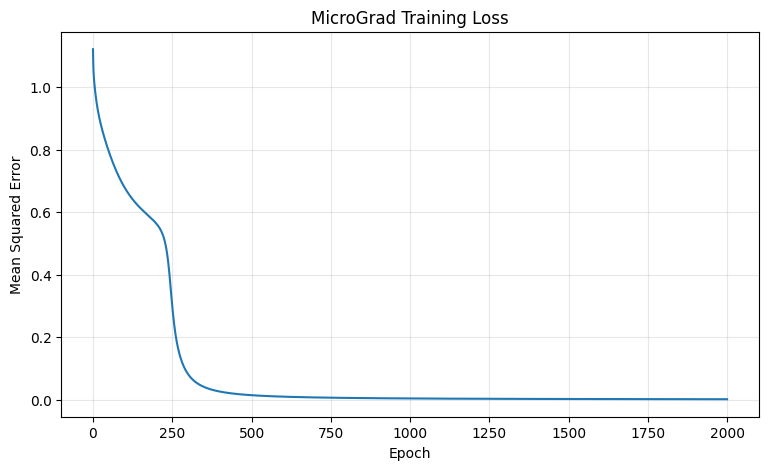

In [10]:

plt.figure(figsize=(9, 5))

plt.plot(loss_history)

plt.title("MicroGrad Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.grid(True, alpha=0.3)

plt.show()


In [11]:

print("Final XOR Predictions")
print("-" * 45)

for inputs, target in zip(X_values, Y):

    prediction = model(inputs)

    predicted_class = 1.0 if prediction.data >= 0 else -1.0

    print(
        f"Input: {[v.data for v in inputs]} "
        f"| Target: {target:+.0f} "
        f"| Prediction: {prediction.data:+.4f} "
        f"| Predicted class: {predicted_class:+.0f}"
    )


Final XOR Predictions
---------------------------------------------
Input: [0.0, 0.0] | Target: -1 | Prediction: -0.9709 | Predicted class: -1
Input: [0.0, 1.0] | Target: +1 | Prediction: +0.9549 | Predicted class: +1
Input: [1.0, 0.0] | Target: +1 | Prediction: +0.9672 | Predicted class: +1
Input: [1.0, 1.0] | Target: -1 | Prediction: -0.9558 | Predicted class: -1



## 9. Conclusion

In this project, we successfully implemented a scalar automatic differentiation engine and a basic neural network API from scratch.

The implementation demonstrated:

- Computational graph construction.
- Mathematical operator overloading.
- Local gradient calculations.
- Backpropagation using the chain rule.
- Topological sorting.
- Neural network construction using Neuron, Layer, and MLP classes.
- Model training using gradient descent.

The XOR experiment demonstrated that the implemented neural network can learn a nonlinear pattern through repeated forward and backward passes.

The project provides a practical understanding of the fundamental mechanisms behind automatic differentiation and neural network training.



## 9. Model Evaluation and Results

After training the MLP, we evaluate its predictions on all four XOR samples.

The predicted values are converted into classes using a threshold of zero:

- Positive predictions represent class +1.
- Negative predictions represent class -1.

We calculate classification accuracy to measure how many samples were classified correctly.


In [12]:

# Evaluate model performance
correct = 0
results = []

for inputs, target in zip(X_values, Y):

    prediction = model(inputs)
    predicted_class = 1.0 if prediction.data >= 0 else -1.0

    is_correct = predicted_class == target

    correct += int(is_correct)

    results.append({
        "Input": [v.data for v in inputs],
        "Actual": target,
        "Prediction": prediction.data,
        "Predicted Class": predicted_class,
        "Correct": is_correct
    })

accuracy = (correct / len(Y)) * 100

print("Model Evaluation")
print("-------------------------")
print(f"Correct predictions: {correct}/{len(Y)}")
print(f"Classification Accuracy: {accuracy:.2f}%")
print(f"Final Training Loss: {loss_history[-1]:.6f}")


Model Evaluation
-------------------------
Correct predictions: 4/4
Classification Accuracy: 100.00%
Final Training Loss: 0.001479



## 8.1 Dataset Loading

The XOR dataset is stored in CSV format and loaded into the notebook before training.

This demonstrates a reproducible data-loading pipeline.


In [13]:

import csv

# Create a data directory
os.makedirs("../data", exist_ok=True)

dataset_path = "../data/xor_dataset.csv"

# Save the XOR dataset
with open(dataset_path, "w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["input_1", "input_2", "target"])

    for inputs, target in zip(X, Y):
        writer.writerow([inputs[0], inputs[1], target])

# Load the dataset from CSV
loaded_X = []
loaded_Y = []

with open(dataset_path, "r") as file:
    reader = csv.DictReader(file)

    for row in reader:
        loaded_X.append([
            float(row["input_1"]),
            float(row["input_2"])
        ])
        loaded_Y.append(float(row["target"]))

print("Dataset loaded from CSV successfully!")
print("Number of samples:", len(loaded_X))
print("Loaded inputs:", loaded_X)
print("Loaded targets:", loaded_Y)


Dataset loaded from CSV successfully!
Number of samples: 4
Loaded inputs: [[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0]]
Loaded targets: [-1.0, 1.0, 1.0, -1.0]


In [14]:

# Convert loaded CSV data into MicroGrad Values
loaded_X_values = [
    [Value(x1), Value(x2)]
    for x1, x2 in loaded_X
]

# Evaluate the trained model
correct = 0

print("FINAL MODEL EVALUATION")
print("=" * 60)

for inputs, target in zip(loaded_X_values, loaded_Y):

    prediction = model(inputs)

    predicted_class = (
        1.0 if prediction.data >= 0 else -1.0
    )

    is_correct = predicted_class == target
    correct += int(is_correct)

    print(
        f"Input: {[v.data for v in inputs]} "
        f"| Target: {target:+.0f} "
        f"| Prediction: {prediction.data:+.4f} "
        f"| Correct: {is_correct}"
    )

accuracy = correct / len(loaded_Y) * 100

print("\nAccuracy:", f"{accuracy:.2f}%")
print("Final Loss:", f"{loss_history[-1]:.6f}")


FINAL MODEL EVALUATION
Input: [0.0, 0.0] | Target: -1 | Prediction: -0.9709 | Correct: True
Input: [0.0, 1.0] | Target: +1 | Prediction: +0.9549 | Correct: True
Input: [1.0, 0.0] | Target: +1 | Prediction: +0.9672 | Correct: True
Input: [1.0, 1.0] | Target: -1 | Prediction: -0.9558 | Correct: True

Accuracy: 100.00%
Final Loss: 0.001479


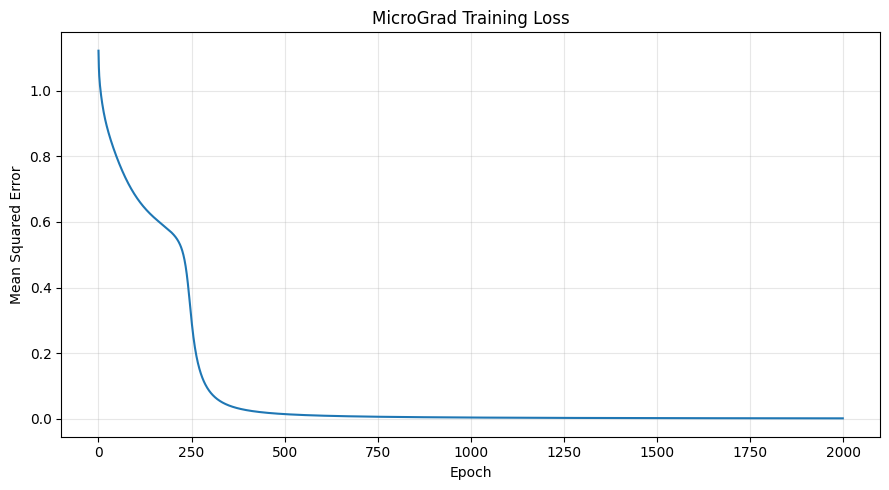

In [15]:
plt.figure(figsize=(9, 5))
plt.plot(loss_history)
plt.title("MicroGrad Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()